# Nonparametric Tests
---

## Experiment: visualize pooled ranks and midranks for ties.

Observations: [7.0, 9.0, 9.0, 13.0, 18.0, 5.0, 9.0, 12.0, 15.0, 19.0]
Pooled midranks: [2.0, 4.0, 4.0, 7.0, 9.0, 1.0, 4.0, 6.0, 8.0, 10.0]


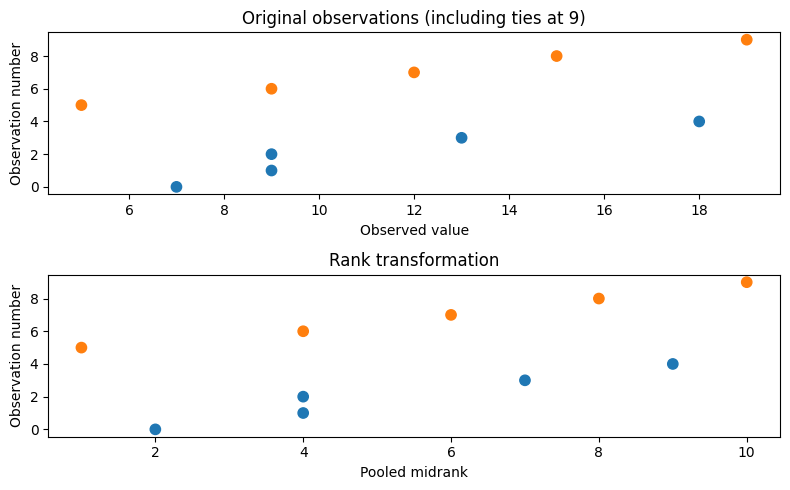

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rankdata

method_a = np.array([7, 9, 9, 13, 18], dtype=float)
method_b = np.array([5, 9, 12, 15, 19], dtype=float)
values = np.concatenate([method_a, method_b])
ranks = rankdata(values, method="average")

print("Observations:", values.tolist())
print("Pooled midranks:", ranks.tolist())

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=False)
colors = ["tab:blue"] * len(method_a) + ["tab:orange"] * len(method_b)
axes[0].scatter(values, np.arange(len(values)), c=colors, s=55)
axes[0].set_xlabel("Observed value")
axes[0].set_ylabel("Observation number")
axes[0].set_title("Original observations (including ties at 9)")
axes[1].scatter(ranks, np.arange(len(ranks)), c=colors, s=55)
axes[1].set_xlabel("Pooled midrank")
axes[1].set_ylabel("Observation number")
axes[1].set_title("Rank transformation")
fig.tight_layout()
fig.savefig("../../images/nonparametric_ranks.png", dpi=160)
plt.show()

## Experiment: derive and verify the exact binomial sign-test p-value.

In [2]:
import numpy as np
from scipy import stats

d = np.array([1, 2, 3, 4, 5, 6], dtype=float)
nonzero = d[d != 0]
positive = np.count_nonzero(nonzero > 0)
n = len(nonzero)

# Exact two-sided binomial tail calculated directly.
p_manual = min(1.0, 2 * stats.binom.cdf(min(positive, n-positive), n, 0.5))
p_scipy = stats.binomtest(positive, n, 0.5).pvalue
print(f"Positive differences: {positive} of {n}")
print(f"Manual p-value: {p_manual:.5f}")
print(f"SciPy p-value:  {p_scipy:.5f}")

Positive differences: 6 of 6
Manual p-value: 0.03125
SciPy p-value:  0.03125


## Experiment: reproduce the exact Mann–Whitney test by enumerating rank allocations.

In [3]:
from itertools import combinations
import numpy as np
from scipy import stats

a = np.array([4, 5, 6, 8])
b = np.array([9, 10, 11, 12])
m, n = len(a), len(b)

rank_sum_a = stats.rankdata(np.r_[a, b])[:m].sum()
u_observed = rank_sum_a - m*(m+1)/2

# Under equal continuous distributions, rank assignments are equiprobable.
possible_u = np.array([
    sum(positions) - m*(m+1)/2
    for positions in combinations(range(1, m+n+1), m)
])
p_exact = min(1.0, 2*min(
    np.mean(possible_u <= u_observed),
    np.mean(possible_u >= u_observed)
))
result = stats.mannwhitneyu(a, b, alternative="two-sided", method="exact")
print(f"R_A={rank_sum_a:.0f}; U_A={u_observed:.0f}")
print(f"Exact p-value={p_exact:.6f}; SciPy p-value={result.pvalue:.6f}")

R_A=10; U_A=0
Exact p-value=0.028571; SciPy p-value=0.028571


## Experiment: estimate probability of superiority and compare empirical distributions.

U_A=5.5; p=0.00613
P(A > B) + 0.5 P(A = B) = 0.086
Cliff's delta (A vs B) = -0.828


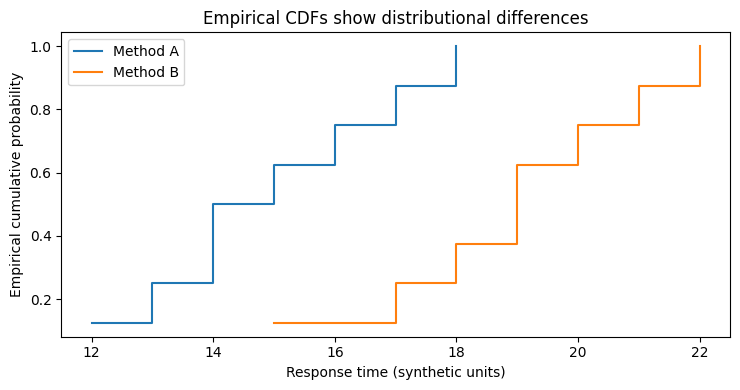

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

a = np.array([12, 14, 13, 16, 18, 15, 17, 14], dtype=float)
b = np.array([15, 19, 18, 22, 20, 17, 21, 19], dtype=float)

u = stats.mannwhitneyu(a, b, alternative="two-sided", method="auto")
prob_superiority = u.statistic / (len(a) * len(b))
cliffs_delta = 2 * prob_superiority - 1
print(f"U_A={u.statistic:.1f}; p={u.pvalue:.5f}")
print(f"P(A > B) + 0.5 P(A = B) = {prob_superiority:.3f}")
print(f"Cliff's delta (A vs B) = {cliffs_delta:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 4))
for vals, label in [(a, "Method A"), (b, "Method B")]:
    ordered = np.sort(vals)
    ax.step(ordered, np.arange(1, len(vals)+1)/len(vals),
            where="post", label=label)
ax.set_xlabel("Response time (synthetic units)")
ax.set_ylabel("Empirical cumulative probability")
ax.set_title("Empirical CDFs show distributional differences")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/nonparametric_ecdf.png", dpi=160)
plt.show()

## Experiment: compute the Wilcoxon signed-rank statistic and its exact p-value.

In [5]:
import numpy as np
from scipy import stats

d = np.array([1, 2, 3, 4, 5, 6], dtype=float)
rank_abs = stats.rankdata(np.abs(d))
w_plus = rank_abs[d > 0].sum()
w_minus = rank_abs[d < 0].sum()
result = stats.wilcoxon(d, alternative="two-sided", method="exact")

print("Absolute-difference ranks:", rank_abs.tolist())
print(f"W+={w_plus:.0f}, W-={w_minus:.0f}, W={min(w_plus, w_minus):.0f}")
print(f"Exact p-value: {result.pvalue:.5f}")

Absolute-difference ranks: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
W+=21, W-=0, W=0
Exact p-value: 0.03125


## Experiment: enumerate signed-rank sign flips with ties and a zero difference.

In [6]:
from itertools import product
import numpy as np
from scipy import stats

# Recorded to one decimal place; one unchanged pair and tied magnitudes.
d = np.array([0.0, 0.5, -0.5, 1.2, 1.2, 2.0, -0.8])
d = np.round(d, 1)
nonzero = d[d != 0]
ranks = stats.rankdata(np.abs(nonzero), method="average")
w_plus = ranks[nonzero > 0].sum()
w_minus = ranks[nonzero < 0].sum()
observed = min(w_plus, w_minus)

# Under symmetric differences, every sign assignment is equally likely,
# even though the magnitudes have ties. Condition on their magnitudes.
null_stats = []
for signs in product([-1, 1], repeat=len(nonzero)):
    plus = ranks[np.array(signs) > 0].sum()
    minus = ranks.sum() - plus
    null_stats.append(min(plus, minus))
p_exact_signflip = np.mean(np.array(null_stats) <= observed + 1e-12)

print(f"Nonzero n={len(nonzero)}, W+={w_plus:.1f}, W-={w_minus:.1f}")
print(f"Exact conditional sign-flip p={p_exact_signflip:.5f}")
print("SciPy asymptotic p (not exact):",
      f"{stats.wilcoxon(nonzero, method='asymptotic').pvalue:.5f}")

Nonzero n=6, W+=16.5, W-=4.5
Exact conditional sign-flip p=0.28125
SciPy asymptotic p (not exact): 0.20590


## Experiment: calculate Kruskal–Wallis from pooled ranks and verify it.

In [7]:
import numpy as np
from scipy import stats

groups = [
    np.array([2, 3, 5, 6, 8]),
    np.array([4, 7, 9, 10, 12]),
    np.array([11, 13, 14, 15, 16]),
]
lengths = [len(g) for g in groups]
pooled = np.concatenate(groups)
ranks = stats.rankdata(pooled)
ranks_by_group = np.split(ranks, np.cumsum(lengths)[:-1])
rank_sums = [r.sum() for r in ranks_by_group]
N, k = len(pooled), len(groups)
H_manual = 12/(N*(N+1))*sum(R**2/n for R,n in zip(rank_sums,lengths)) - 3*(N+1)
result = stats.kruskal(*groups)
print("Rank sums:", rank_sums)
print(f"Manual H={H_manual:.2f}; SciPy H={result.statistic:.2f}")
print(f"Approximate chi-square p={result.pvalue:.6f}")
print(f"Approximate epsilon_H^2={(H_manual-k+1)/(N-k):.3f}")

Rank sums: [19.0, 37.0, 64.0]
Manual H=10.26; SciPy H=10.26
Approximate chi-square p=0.005917
Approximate epsilon_H^2=0.688


## Experiment: run pairwise Mann–Whitney comparisons with Holm-adjusted p-values.

In [8]:
from itertools import combinations
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

groups = {
    "A": [2, 3, 5, 6, 8],
    "B": [4, 7, 9, 10, 12],
    "C": [11, 13, 14, 15, 16],
}
pairs = list(combinations(groups.keys(), 2))
p_raw = [stats.mannwhitneyu(groups[a], groups[b],
                          alternative="two-sided", method="exact").pvalue
         for a,b in pairs]
reject, p_adjusted, _, _ = multipletests(p_raw, method="holm", alpha=0.05)
for (a,b), raw, adj, significant in zip(pairs, p_raw, p_adjusted, reject):
    print(f"{a} vs {b}: raw p={raw:.5f}, Holm p={adj:.5f}, reject={significant}")

A vs B: raw p=0.09524, Holm p=0.09524, reject=False
A vs C: raw p=0.00794, Holm p=0.02381, reject=True
B vs C: raw p=0.01587, Holm p=0.03175, reject=True


## Experiment: calculate Friedman Q and enumerate its exact small-sample null distribution.

In [9]:
from itertools import permutations, product
import numpy as np
from scipy import stats

# Rows are participants (blocks), columns are conditions.
data = np.array([
    [12, 15, 21],
    [14, 17, 20],
    [13, 18, 19],
    [16, 15, 23],
    [11, 14, 18],
], dtype=float)
n, k = data.shape
ranks = np.array([stats.rankdata(row) for row in data])
rank_sums = ranks.sum(axis=0)
q = 12/(n*k*(k+1)) * np.sum(rank_sums**2) - 3*n*(k+1)
asymptotic = stats.friedmanchisquare(*data.T)

# Enumerate all 6^5 possible within-person condition rank assignments.
rank_orders = np.array(list(permutations(range(1, k+1))), dtype=float)
indices = np.array(list(product(range(len(rank_orders)), repeat=n)))
null_rank_sums = rank_orders[indices].sum(axis=1)
null_q = 12/(n*k*(k+1))*np.sum(null_rank_sums**2, axis=1)-3*n*(k+1)
p_exact = np.mean(null_q >= q - 1e-12)

print("Rank sums:", rank_sums)
print(f"Q={q:.2f}, asymptotic p={asymptotic.pvalue:.6f}")
print(f"Exact p={p_exact:.6f}, Kendall W={q/(n*(k-1)):.2f}")

Rank sums: [ 6.  9. 15.]
Q=8.40, asymptotic p=0.014996
Exact p=0.008488, Kendall W=0.84


## Experiment: visualize matched observations without losing participant identities.

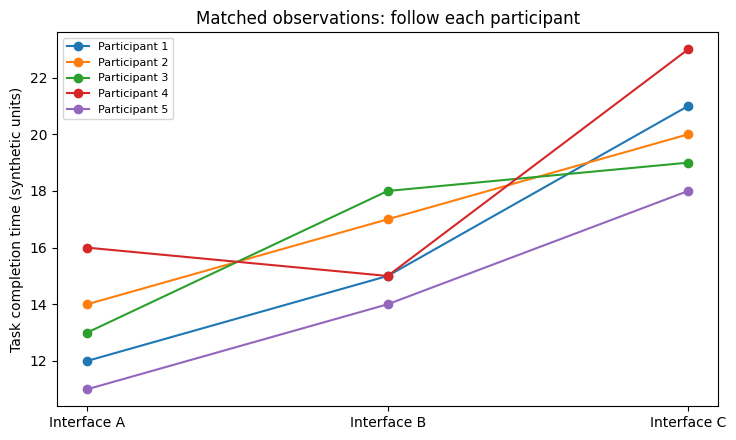

In [10]:
import numpy as np
import matplotlib.pyplot as plt

completion = np.array([
    [12, 15, 21],
    [14, 17, 20],
    [13, 18, 19],
    [16, 15, 23],
    [11, 14, 18],
])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for person, row in enumerate(completion, start=1):
    ax.plot(range(3), row, marker="o", label=f"Participant {person}")
ax.set_xticks(range(3), ["Interface A", "Interface B", "Interface C"])
ax.set_ylabel("Task completion time (synthetic units)")
ax.set_title("Matched observations: follow each participant")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../../images/nonparametric_matched_profiles.png", dpi=160)
plt.show()

## Experiment: show why equal population medians do not imply equal distributions.

In [11]:
import numpy as np

rng = np.random.default_rng(2026)
N = 300_000
x = rng.exponential(scale=1.0, size=N) - np.log(2.0)
y = rng.normal(0.0, 1.0, size=N)

print(f"Sample median X: {np.median(x):.4f}")
print(f"Sample median Y: {np.median(y):.4f}")
print(f"P(X > Y) estimated from independent pairs: {np.mean(x > y):.4f}")
print("Theoretical population medians are both zero.")

Sample median X: -0.0046
Sample median Y: -0.0023
P(X > Y) estimated from independent pairs: 0.5561
Theoretical population medians are both zero.


## Experiment: perform an exact label-permutation rank comparison with tied ratings.

In [12]:
import numpy as np
from scipy import stats

# Independent users; small ordinal samples with repeated ratings.
a = np.array([2, 3, 3, 4, 4])
b = np.array([3, 4, 4, 5, 5])

def superiority_count(x, y):
    # Exactly matches Mann–Whitney U with midrank handling of ties.
    return np.sum(x[:, None] > y[None, :]) + 0.5*np.sum(x[:, None] == y[None, :])

result = stats.permutation_test(
    (a, b), superiority_count,
    permutation_type="independent",
    n_resamples=np.inf,     # all C(10, 5) = 252 reallocations
    alternative="two-sided",
    vectorized=False,
)
theta = superiority_count(a, b) / (len(a) * len(b))
print(f"Observed P(A > B) + 0.5 P(tie) = {theta:.3f}")
print(f"Exact permutation p-value = {result.pvalue:.6f}")
print("Possible label reallocations:", 252)

Observed P(A > B) + 0.5 P(tie) = 0.200
Exact permutation p-value = 0.190476
Possible label reallocations: 252
